<a href="https://colab.research.google.com/github/Sn0w616/Taller-Bussiness-Analytics---AN-LISIS-PREDICTIVO-DE-DATOS/blob/main/Taller_analisis_predictivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica: Análisis predictivo de ventas con Python

**Asignatura:** Business Analytics
**Por:** Camilo Andrés González López  
**Fuente de datos:** Archivo Excel `taller_business_analytics.xlsx` - `Datos_Limpios`.

## Objetivo general

Implementar un modelo de análisis predictivo utilizando Python para estudiar el comportamiento histórico de las ventas y estimar su valor para un periodo futuro, apoyando la toma de decisiones empresariales.

## Objetivos específicos

- Explorar y preparar los datos de ventas.
- Identificar variables relevantes para el análisis.
- Construir un modelo predictivo de regresión lineal.
- Evaluar su desempeño mediante métricas estadísticas.
- Visualizar e interpretar las predicciones obtenidas.

## Contexto conceptual

El análisis descriptivo permite comprender qué ocurrió en un periodo anterior mediante resúmenes, estadísticas y gráficos. En cambio, el análisis predictivo utiliza patrones identificados en los datos históricos para estimar posibles resultados futuros.

## 1. Importación de librerías

Se utilizarán las siguientes bibliotecas:

- `pandas`: lectura, limpieza y organización de datos.
- `numpy`: operaciones matemáticas y variables estacionales.
- `matplotlib`: generación de visualizaciones.
- `scikit-learn`: construcción y evaluación del modelo predictivo.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 2. Carga de los datos

Se cargará el archivo Excel proporcionado en la actividad anterior. Se seleccionará específicamente la hoja `Datos_Limpios`, que contiene los registros preparados para el análisis.

In [16]:
from google.colab import files

uploaded = files.upload()

archivo = next(iter(uploaded))

df = pd.read_excel(
    archivo,
    sheet_name="Datos_Limpios"
)

print("Archivo cargado:", archivo)
print("Cantidad de filas y columnas:", df.shape)

display(df.head())

Saving taller_business_analytics.xlsx to taller_business_analytics (1).xlsx
Archivo cargado: taller_business_analytics (1).xlsx
Cantidad de filas y columnas: (420, 7)


,Fecha,Region,Producto,Vendedor,Unidades,PrecioUnitario,Total
0,2026-06-01,Bogotá,Webcam,Luis Peña,3,95000,285000
1,2026-01-15,Barranquilla,Webcam,Luis Peña,2,115000,230000
2,2025-06-23,Cali,Mouse,Diana Gomez,3,60000,180000
3,2026-04-16,Barranquilla,Monitor,Ana Torres,3,660000,1980000
4,2025-10-24,Cali,Webcam,Ana Torres,8,85000,680000


## 3. Exploración de los datos

Antes de construir el modelo, es necesario conocer la estructura del conjunto de datos. Se revisarán los nombres de las columnas, los tipos de datos, los valores faltantes y las estadísticas descriptivas.

In [17]:
# Mostrar los nombres de las columnas
print("Columnas disponibles:")
print(df.columns.tolist())

# Mostrar los tipos de datos
print("\nTipos de datos:")
display(df.dtypes.to_frame(name="Tipo de dato"))

# Revisar los valores faltantes
print("\nValores faltantes:")
display(df.isnull().sum().to_frame(name="Cantidad"))

# Estadísticas descriptivas
print("\nEstadísticas descriptivas:")
display(df.describe(include="all").T)

# Revisar el periodo de los registros
df["Fecha"] = pd.to_datetime(df["Fecha"], errors="coerce")

print("\nFecha inicial:", df["Fecha"].min())
print("Fecha final:", df["Fecha"].max())

Columnas disponibles:
['Fecha', 'Region', 'Producto', 'Vendedor', 'Unidades', 'PrecioUnitario', 'Total']

Tipos de datos:


,Tipo de dato
Fecha,datetime64[ns]
Region,object
Producto,object
Vendedor,object
Unidades,int64
PrecioUnitario,int64
Total,int64



Valores faltantes:


,Cantidad
Fecha,0
Region,0
Producto,0
Vendedor,0
Unidades,0
PrecioUnitario,0
Total,0



Estadísticas descriptivas:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Fecha,420,NaN,NaN,NaN,2025-10-01 10:37:42.857142784,2025-01-02 00:00:00,2025-05-05 18:00:00,2025-09-29 12:00:00,2026-02-27 00:00:00,2026-06-28 00:00:00,NaN
Region,420,8,Cali,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Producto,420,7,Audífonos,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vendedor,420,6,Sofia Reyez,79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unidades,420.0,NaN,NaN,NaN,7.459524,0.0,4.0,7.0,11.0,15.0,4.270762
PrecioUnitario,420.0,NaN,NaN,NaN,634333.333333,50000.0,110000.0,150000.0,650000.0,2820000.0,928313.922262
Total,420.0,NaN,NaN,NaN,4565130.952381,0.0,590000.0,1310000.0,4925000.0,42000000.0,7960149.563214



Fecha inicial: 2025-01-02 00:00:00
Fecha final: 2026-06-28 00:00:00


## 4. Limpieza y preparación de los datos

Se verificará que las fechas sean válidas y que la columna `Total` contenga valores numéricos. Se eliminarán los registros que no tengan fecha o valor de venta válido, así como los valores negativos de ventas, que no corresponden al escenario planteado.

No se reemplazarán los valores faltantes por cifras inventadas. Finalmente, se ordenarán los registros cronológicamente.

In [18]:
# Comprobar que existan las columnas necesarias
columnas_requeridas = ["Fecha", "Total"]

for columna in columnas_requeridas:
    if columna not in df.columns:
        raise ValueError(
            f"No se encontró la columna requerida: {columna}"
        )

# Convertir los campos a sus tipos correspondientes
df["Fecha"] = pd.to_datetime(
    df["Fecha"],
    errors="coerce"
)

df["Total"] = pd.to_numeric(
    df["Total"],
    errors="coerce"
)

# Eliminar registros con fecha o venta inválida
datos = df.dropna(
    subset=["Fecha", "Total"]
).copy()

# Excluir valores negativos
datos = datos[datos["Total"] >= 0].copy()

# Ordenar cronológicamente
datos = datos.sort_values("Fecha").reset_index(drop=True)

print("Registros originales:", len(df))
print("Registros válidos:", len(datos))
print("Registros excluidos:", len(df) - len(datos))

display(datos.head())

Registros originales: 420
Registros válidos: 420
Registros excluidos: 0


,Fecha,Region,Producto,Vendedor,Unidades,PrecioUnitario,Total
0,2025-01-02,Barranquilla,Mouse,Luis Peña,11,50000,550000
1,2025-01-03,Barranquilla,Audífonos,Carlos Ruiz,14,160000,2240000
2,2025-01-05,Bucaramanga,Webcam,Jorge Salas,13,105000,1365000
3,2025-01-08,Bogotá,Monitor,Sofia Reyez,3,650000,1950000
4,2025-01-09,Cali,Audífonos,Jorge Salas,4,140000,560000


## 5. Análisis descriptivo de las ventas

El análisis descriptivo permite identificar características de las ventas antes de realizar predicciones.

Se calcularán las ventas totales, el promedio por transacción y las unidades vendidas. También se visualizarán las ventas agrupadas por producto.

Estos resultados describen el comportamiento registrado, pero todavía no constituyen predicciones de valores futuros.

Ventas totales registradas:
$1,917,355,000

Promedio de venta por registro:
$4,565,130.95

Unidades totales vendidas:
3133


,Ventas acumuladas
Producto,
Laptop,1220920000
Monitor,276810000
Impresora,209350000
Audífonos,85200000
Teclado,50820000
Webcam,46475000
Mouse,27780000


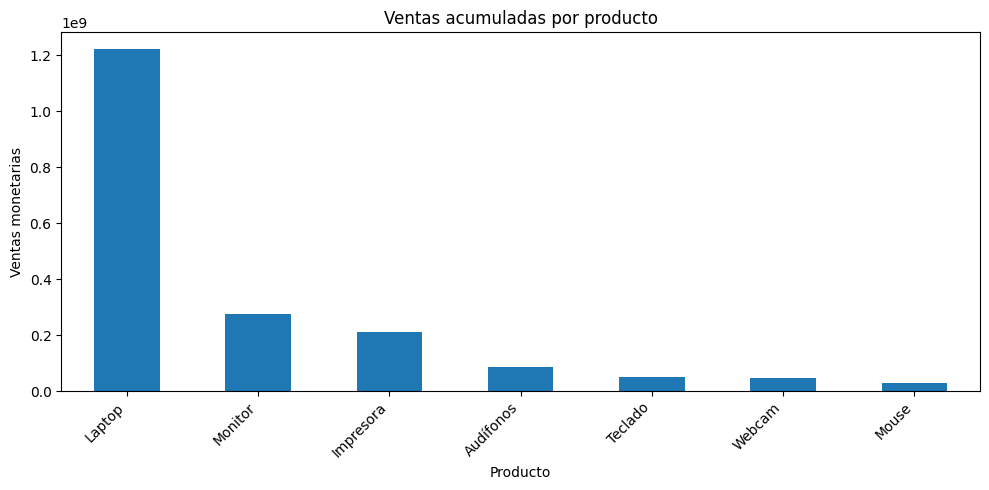

In [19]:
print("Ventas totales registradas:")
print(f"${datos['Total'].sum():,.0f}")

print("\nPromedio de venta por registro:")
print(f"${datos['Total'].mean():,.2f}")

if "Unidades" in datos.columns:
    print("\nUnidades totales vendidas:")
    print(datos["Unidades"].sum())

# Ventas por producto
if "Producto" in datos.columns:
    ventas_producto = (
        datos.groupby("Producto")["Total"]
        .sum()
        .sort_values(ascending=False)
    )

    display(
        ventas_producto.to_frame(
            name="Ventas acumuladas"
        )
    )

    ventas_producto.plot(
        kind="bar",
        figsize=(10, 5)
    )

    plt.title("Ventas acumuladas por producto")
    plt.xlabel("Producto")
    plt.ylabel("Ventas monetarias")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 6. Construcción de la serie de ventas mensuales

Para realizar el análisis predictivo, se agruparán los registros por mes y se sumará la columna `Total`.

La variable objetivo será `VentasMensuales`. El propósito es que el modelo aprenda de la evolución de las ventas a lo largo del tiempo.

Se utilizarán las siguientes variables predictoras:

- **Tiempo:** representa el orden cronológico de cada mes.
- **Ventas del mes anterior:** permite incorporar el comportamiento reciente.
- **Variables estacionales:** representan el mes del año mediante funciones seno y coseno.

Si un mes no tiene registros, se contabilizará como cero ventas. Este supuesto es válido únicamente si la base contiene todas las transacciones del periodo y la ausencia de registros significa que no hubo ventas.

In [20]:
# Agrupar las ventas por mes
mensual = (
    datos.set_index("Fecha")["Total"]
    .resample("MS")
    .sum()
    .to_frame(name="VentasMensuales")
)

# Crear un índice temporal
mensual["t"] = np.arange(len(mensual))

# Incorporar las ventas del mes anterior
mensual["VentasMesAnterior"] = (
    mensual["VentasMensuales"].shift(1)
)

# Representar el mes del año de forma cíclica
numero_mes = mensual.index.month

mensual["MesSeno"] = np.sin(
    2 * np.pi * numero_mes / 12
)

mensual["MesCoseno"] = np.cos(
    2 * np.pi * numero_mes / 12
)

print("Cantidad de meses:", len(mensual))
print(
    "Periodo:",
    mensual.index.min().strftime("%Y-%m"),
    "hasta",
    mensual.index.max().strftime("%Y-%m")
)

display(mensual.head(10))

Cantidad de meses: 18
Periodo: 2025-01 hasta 2026-06


,VentasMensuales,t,VentasMesAnterior,MesSeno,MesCoseno
Fecha,,,,,
2025-01-01,35850000,0,NaN,5.000000e-01,8.660254e-01
2025-02-01,80410000,1,35850000.0,8.660254e-01,5.000000e-01
2025-03-01,96985000,2,80410000.0,1.000000e+00,6.123234e-17
2025-04-01,137220000,3,96985000.0,8.660254e-01,-5.000000e-01
2025-05-01,148905000,4,137220000.0,5.000000e-01,-8.660254e-01
2025-06-01,121455000,5,148905000.0,1.224647e-16,-1.000000e+00
2025-07-01,120395000,6,121455000.0,-5.000000e-01,-8.660254e-01
2025-08-01,75970000,7,120395000.0,-8.660254e-01,-5.000000e-01
2025-09-01,162675000,8,75970000.0,-1.000000e+00,-1.836970e-16


## 7. Visualización de las ventas mensuales

Se elaborará un gráfico de líneas para observar la evolución de las ventas mensuales.

La visualización permitirá reconocer variaciones, tendencias y posibles comportamientos estacionales. Sin embargo, observar un patrón en los datos históricos no garantiza que se repita en el futuro.

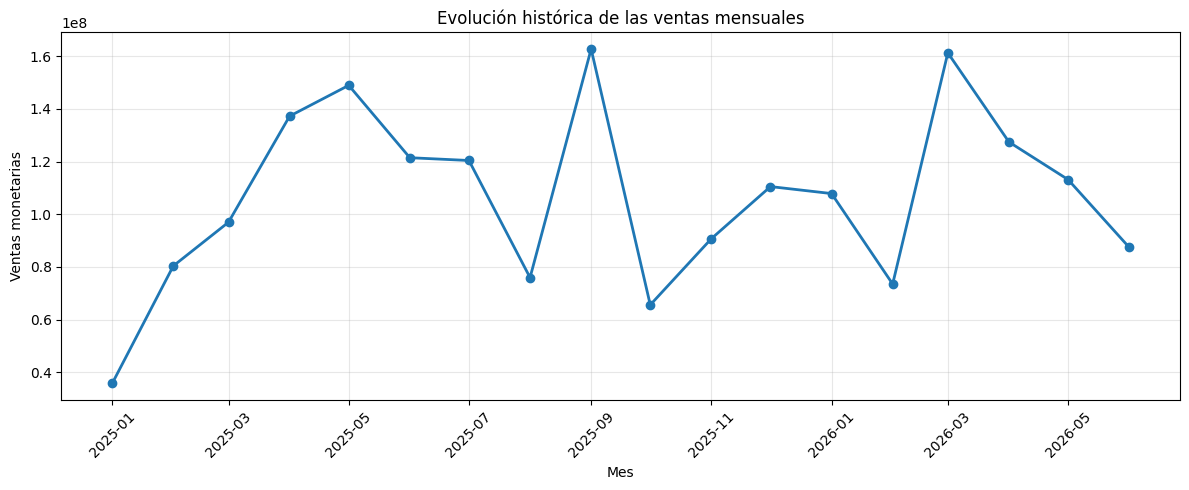

In [21]:
plt.figure(figsize=(12, 5))

plt.plot(
    mensual.index,
    mensual["VentasMensuales"],
    marker="o",
    linewidth=2
)

plt.title("Evolución histórica de las ventas mensuales")
plt.xlabel("Mes")
plt.ylabel("Ventas monetarias")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Selección de variables y división de los datos

Se seleccionarán las variables predictoras y la variable objetivo del modelo.

Los datos se dividirán respetando el orden cronológico. Los primeros meses se utilizarán para entrenar el modelo y los últimos meses se reservarán para evaluar sus predicciones.

Esta estrategia permite simular una situación real en la que se utilizan datos pasados para predecir periodos posteriores.

In [22]:
# Seleccionar las variables
variables = [
    "t",
    "VentasMesAnterior",
    "MesSeno",
    "MesCoseno"
]

objetivo = "VentasMensuales"

# Eliminar la primera fila, que no tiene ventas del mes anterior
model_data = mensual.dropna(
    subset=variables + [objetivo]
).copy()

# Reservar los últimos meses para la evaluación
n_test = max(3, int(np.ceil(len(model_data) * 0.20)))

if len(model_data) - n_test < 5:
    raise ValueError(
        "Hay muy pocos meses para entrenar y evaluar "
        "el modelo. Se necesitan más datos históricos."
    )

train = model_data.iloc[:-n_test]
test = model_data.iloc[-n_test:]

X_train = train[variables]
y_train = train[objetivo]

X_test = test[variables]
y_test = test[objetivo]

# Crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Generar predicciones para los meses de prueba
predicciones = modelo.predict(X_test)

print("Meses para entrenamiento:", len(train))
print("Meses para prueba:", len(test))
print("Modelo entrenado correctamente.")

Meses para entrenamiento: 13
Meses para prueba: 4
Modelo entrenado correctamente.


## 9. Evaluación del modelo predictivo

Para evaluar el desempeño del modelo se utilizarán tres métricas:

- **MAE:** error absoluto medio. Expresa cuánto se alejan, en promedio, las predicciones de los valores reales.
- **RMSE:** raíz del error cuadrático medio. Penaliza con mayor intensidad los errores grandes.
- **R²:** coeficiente de determinación. Indica qué tan bien se ajustan las predicciones a los valores reales evaluados. Puede ser negativo cuando el modelo tiene un desempeño deficiente.

El MAE y el RMSE se expresan en las mismas unidades monetarias que las ventas. Las métricas se calcularán exclusivamente sobre el periodo de prueba.

In [23]:
mae = mean_absolute_error(
    y_test,
    predicciones
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        predicciones
    )
)

r2 = r2_score(
    y_test,
    predicciones
)

metricas = pd.DataFrame({
    "Métrica": ["MAE", "RMSE", "R²"],
    "Resultado": [mae, rmse, r2]
})

display(metricas.round(4))

print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²: {r2:.4f}")

,Métrica,Resultado
0,MAE,3.738961e+07
1,RMSE,4.874809e+07
2,R²,-2.347500e+00


MAE: $37,389,611.44
RMSE: $48,748,088.63
R²: -2.3475


## 10. Comparación de ventas reales y predichas

Se compararán los valores reales de los meses de prueba con las predicciones generadas por el modelo.

La gráfica permitirá identificar si las estimaciones siguen el comportamiento observado y en qué periodos aparecen diferencias importantes.

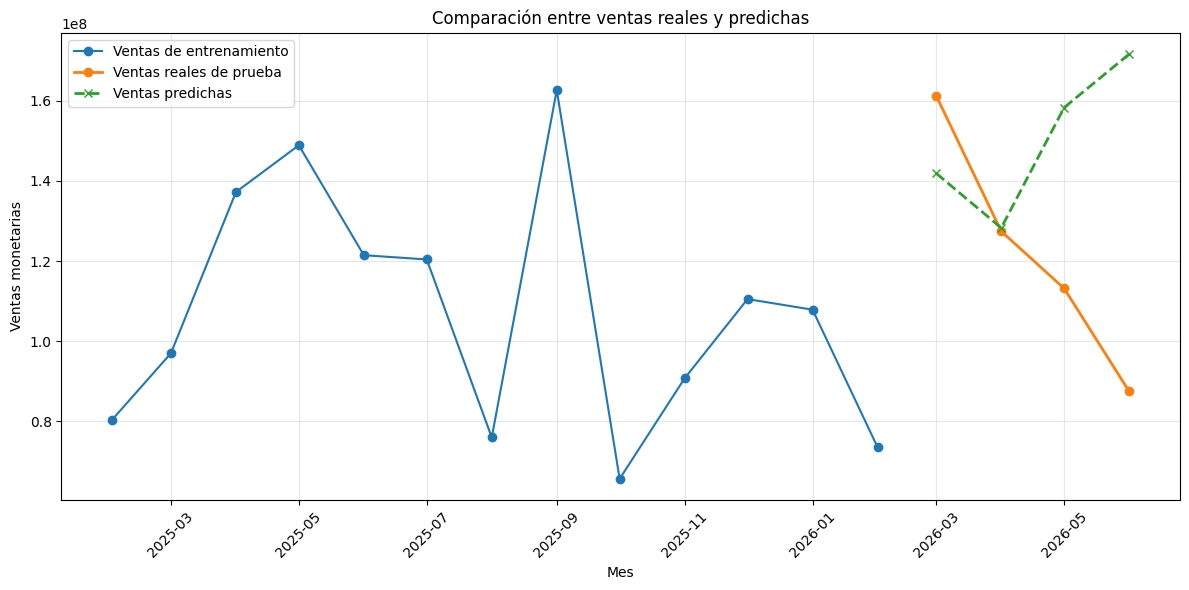

In [25]:
plt.figure(figsize=(12, 6))

plt.plot(
    train.index,
    y_train,
    marker="o",
    label="Ventas de entrenamiento"
)

plt.plot(
    test.index,
    y_test,
    marker="o",
    linewidth=2,
    label="Ventas reales de prueba"
)

plt.plot(
    test.index,
    predicciones,
    marker="x",
    linestyle="--",
    linewidth=2,
    label="Ventas predichas"
)

plt.title("Comparación entre ventas reales y predichas")
plt.xlabel("Mes")
plt.ylabel("Ventas monetarias")
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 11. Análisis de los errores de predicción

Se construirá una tabla para comparar las ventas reales con las estimadas por el modelo.

El error se calculará restando las ventas predichas a las reales:

**Error = Ventas reales − Ventas predichas**

Un error positivo indica que el modelo subestimó las ventas, mientras que uno negativo indica que las sobreestimó.

In [26]:
resultados = pd.DataFrame(
    {
        "VentasReales": y_test,
        "VentasPredichas": predicciones
    },
    index=test.index
)

resultados.index.name = "Mes"

resultados["Error"] = (
    resultados["VentasReales"]
    - resultados["VentasPredichas"]
)

resultados["ErrorAbsoluto"] = (
    resultados["Error"].abs()
)

display(resultados.round(2))

,VentasReales,VentasPredichas,Error,ErrorAbsoluto
Mes,,,,
2026-03-01,161230000,1.418956e+08,19334376.57,19334376.57
2026-04-01,127420000,1.282741e+08,-854125.41,854125.41
2026-05-01,113155000,1.583122e+08,-45157225.54,45157225.54
2026-06-01,87455000,1.716677e+08,-84212718.26,84212718.26


## 12. Predicción de las ventas del siguiente mes

Una vez evaluado el modelo, se volverá a entrenar utilizando todos los meses históricos disponibles. Esto permite aprovechar los datos conocidos para estimar el siguiente periodo.

La predicción es una estimación estadística y no una garantía del comportamiento futuro de las ventas. Su confiabilidad depende de la calidad de los datos, de la estabilidad del negocio y del desempeño obtenido durante la evaluación.

In [27]:
# Entrenar el modelo final con todos los meses históricos disponibles
X_completo = model_data[variables]
y_completo = model_data[objetivo]

modelo_final = LinearRegression()
modelo_final.fit(X_completo, y_completo)

# Definir el siguiente mes
ultimo_mes = mensual.index.max()

siguiente_mes = (
    ultimo_mes + pd.offsets.MonthBegin(1)
)

# Preparar las variables predictoras futuras
mes_numero = siguiente_mes.month

datos_futuros = pd.DataFrame([{
    "t": len(mensual),
    "VentasMesAnterior": mensual["VentasMensuales"].iloc[-1],
    "MesSeno": np.sin(2 * np.pi * mes_numero / 12),
    "MesCoseno": np.cos(2 * np.pi * mes_numero / 12)
}])

# Generar la predicción
prediccion_futura = modelo_final.predict(
    datos_futuros[variables]
)[0]

print(
    "Mes estimado:",
    siguiente_mes.strftime("%Y-%m")
)

print(
    f"Ventas estimadas: ${prediccion_futura:,.2f}"
)

if prediccion_futura < 0:
    print(
        "Advertencia: el modelo produjo una estimación negativa. "
        "No debe interpretarse como una venta posible; "
        "revisa los datos y considera otro modelo."
    )

Mes estimado: 2026-07
Ventas estimadas: $128,265,821.29


### Interpretación de las métricas del modelo

Los resultados obtenidos mediante el modelo de regresión lineal muestran limitaciones importantes en la estimación de las ventas mensuales. El error absoluto medio (MAE) fue de 37.389.611,44,lo que indica que las predicciones presentaron una diferencia absoluta promedio de aproximadamente 37,4 millones respecto a los valores reales del conjunto de prueba.

Por su parte, la raíz del error cuadrático medio (RMSE) fue de 48.748.088,63. Esta métrica otorga mayor peso a los errores de mayor magnitud, por lo que su valor superior al MAE sugiere que algunos errores podrían ser considerablemente grandes.

El coeficiente de determinación (R²) fue de −2,3475. Este resultado indica que, durante el periodo evaluado, el modelo tuvo un desempeño inferior al de una referencia que predijera la media de las ventas observadas en ese mismo periodo.

En consecuencia, el modelo implementado no presenta, en su estado actual, un desempeño suficiente para respaldar decisiones empresariales importantes sin validaciones adicionales. Entre las posibles causas se encuentran la cantidad limitada de observaciones mensuales, las variaciones en las ventas y la ausencia de variables explicativas como los productos vendidos, las promociones, los cambios de precios o las condiciones comerciales.

## 14. Conclusiones

El desarrollo de esta práctica permite aplicar un proceso básico de análisis predictivo utilizando datos históricos de ventas. A través de Python se realiza la exploración y preparación de la información, la selección de variables, el entrenamiento de un modelo de regresión lineal y la evaluación de sus predicciones.

La comparación entre las ventas reales y estimadas, junto con las métricas de error, permite valorar las limitaciones y la utilidad del modelo para apoyar la planificación empresarial.

A diferencia del análisis descriptivo, que resume el comportamiento pasado, el análisis predictivo busca estimar resultados futuros. No obstante, la calidad de estas estimaciones depende de los datos disponibles y de la capacidad del modelo para representar el comportamiento del negocio.

## 15. Referencias

- Guía Analítica Empresarial. Capítulo: Análisis predictivo. Material académico proporcionado para la actividad.
- *What is Predictive Analytics?* Artículo asignado para la actividad. Completar con el autor, la fecha de publicación y el enlace exacto de la versión consultada.
- scikit-learn. (s. f.). *LinearRegression*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
- pandas. (s. f.). *pandas documentation*. https://pandas.pydata.org/docs/